# Module 1: Probability Foundations, Tested on Real Data

*By Héctor Ornelas*

In this notebook I review the first block of MIT's 15.455x course, *Mathematical Methods for
Quantitative Finance*. The course teaches probability with simulated numbers, and that is a good way
to check that a formula is right, but it does not say if the formula works with real prices. So I took
the same topics, in the same order, and tested each one with real market data, from the point of view
of a person who saves in Mexican pesos.

Some choices I made at the start:

- **Same topics as the course.** The sections follow the order of the first module, from a single
  random variable to diversification. What changes is that each exercise uses real prices instead of
  simulated ones.
- **Mexican point of view.** I use the Mexican stock index (IPC), the peso against the dollar, and US
  assets converted to pesos, because that is how a person in Mexico actually sees their money.
- **Self-contained.** I use `numpy`, `pandas` only to read and align the data, and `matplotlib`.
  When I need a formula, like a binomial probability or the normal CDF, I write it myself, so the math
  stays visible.
- **Reproducible.** The prices come from `download_data.py` and are saved in `data/prices.csv`, and
  the seed is fixed at 37, so every run gives the same numbers and my comments stay correct.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import comb, erf, erfc, exp, sqrt

# fix the seed so every run gives exactly the same numbers
np.random.seed(37)

# one common style for all the plots: size, a light grid, and font size
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 11})

# standard normal CDF and upper tail, written with the error function
def normal_cdf(x):
    return 0.5 * (1 + erf(x / sqrt(2)))

def normal_tail(x):
    # P(Z > x); erfc keeps precision far in the tail, where 1 - cdf rounds to 0
    return 0.5 * erfc(x / sqrt(2))

def log_returns(cols):
    # keep only the days where every column has a price, so each row covers the same period
    p = prices[cols].dropna()
    return np.log(p).diff().dropna()

prices = pd.read_csv("data/prices.csv", index_col=0, parse_dates=True)

# dollar assets measured in pesos, with the FRED exchange rate of the same day
for col in ["SPY", "EEM", "TLT", "GLD"]:
    prices[col + "_MXN"] = prices[col] * prices["USDMXN"]

print(f"{prices.index.min().date()} to {prices.index.max().date()}")
print(prices[["IPC", "SPY", "USDMXN", "SPY_MXN"]].dropna().tail(3).round(2))

2005-01-03 to 2026-10-14
                 IPC     SPY  USDMXN   SPY_MXN
Date                                          
2026-10-07  64653.33  777.22   17.99  13980.56
2026-10-08  64986.91  773.93   18.17  14063.00
2026-10-09  66048.57  778.57   18.40  14324.91


## 0. Before starting: checking the data

Before using any number, I want to know if it is correct. The most important series in this notebook
is the exchange rate, because every dollar asset converted to pesos depends on it. For example, to
know what the SPY did for a Mexican on a given day, I multiply the SPY price by the exchange rate of
that same day, and that only works if both numbers really belong to the same day.

**Exercise 0. Is the exchange rate on the right day?** I compare two sources of USD/MXN, Yahoo Finance
and the Federal Reserve (FRED). If a source is correct, the correlation between the SPY and the peso
on the same day should be similar in every period.

In [2]:
lr = log_returns(["SPY", "USDMXN_YF", "USDMXN"])

# correlation between SPY and the peso on the same day, and against the peso of the next day
print(f"{'period':<12}{'Yahoo same':>12}{'Yahoo next':>12}{'FRED same':>12}{'FRED next':>12}")
for a, b in [("2005", "2012"), ("2013", "2019"), ("2020", "2026")]:
    s = lr.loc[a:b]
    row = []
    for fx in ["USDMXN_YF", "USDMXN"]:
        row += [s["SPY"].corr(s[fx]), s["SPY"].corr(s[fx].shift(-1))]
    print(f"{a}-{b:<7}" + "".join(f"{x:>12.2f}" for x in row))

period        Yahoo same  Yahoo next   FRED same   FRED next
2005-2012          -0.65        0.14       -0.38       -0.23
2013-2019          -0.32       -0.02       -0.32       -0.04
2020-2026          -0.04       -0.44       -0.36       -0.16


In 2020–2026 the same-day correlation of Yahoo almost disappears ($-0.04$), and the next-day
correlation becomes strong ($-0.44$). The relationship did not disappear, it moved exactly one day,
which is what happens when a series is dated one day late. FRED, which measures the same exchange rate
independently, gives a similar same-day number in the three periods ($-0.38$, $-0.32$ and $-0.36$), so
the market did not change, the Yahoo series did.

The table only says that the problem starts somewhere after 2013. To find when, I repeat the
comparison in rolling windows of six months.

next-day correlation stronger than same-day: 0% of the days before 2018, 98% of the days from 2019
first window where it stays stronger for a year ends on 2018-08-31
FRED same-day correlation negative on 99% of the days


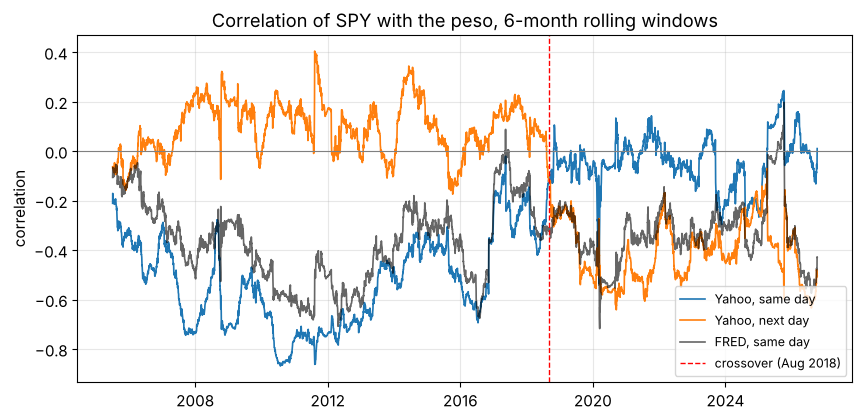

In [3]:
# when did the shift start? correlation of SPY with the Yahoo peso in 6-month (126-day) rolling windows
w = 126
same = lr["SPY"].rolling(w).corr(lr["USDMXN_YF"])
nxt = lr["SPY"].rolling(w).corr(lr["USDMXN_YF"].shift(-1))
fred = lr["SPY"].rolling(w).corr(lr["USDMXN"])
roll = pd.DataFrame({"same": same, "next": nxt, "fred": fred}).dropna()

# first window end after which the next-day correlation stays stronger for at least a year
stronger = roll["next"] < roll["same"]
for t in roll.index:
    if stronger[t] and stronger.loc[t:].iloc[:252].mean() > 0.95:
        break
print(f"next-day correlation stronger than same-day: {stronger[:'2017'].mean():.0%} of the days before 2018, "
      f"{stronger['2019':].mean():.0%} of the days from 2019")
print(f"first window where it stays stronger for a year ends on {t.date()}")
print(f"FRED same-day correlation negative on {(roll['fred'] < 0).mean():.0%} of the days")

plt.figure(figsize=(10, 4.5))
plt.plot(roll.index, roll["same"], lw=1.2, label="Yahoo, same day")
plt.plot(roll.index, roll["next"], lw=1.2, label="Yahoo, next day")
plt.plot(roll.index, roll["fred"], lw=1.2, color="black", alpha=0.6, label="FRED, same day")
plt.axhline(0, color="gray", lw=0.8)
plt.axvline(t, color="red", ls="--", lw=1, label=f"crossover ({t:%b %Y})")
plt.title("Correlation of SPY with the peso, 6-month rolling windows")
plt.ylabel("correlation"); plt.legend(fontsize=9); plt.show()

The two Yahoo lines cross in the second half of 2018. Before 2018 the next-day correlation was never
stronger than the same-day one, and from 2019 it is stronger on 98% of the days, while the FRED line
is negative on 99% of the days and shows no break in 2018. So Yahoo started to date the exchange rate one day late around 2018, and
nothing in the data says it. This is why I use FRED for the rest of the notebook.
FRED is not perfect either. It measures the rate at noon in New York and the SPY
closes around four hours later, so part of the afternoon move appears on the next day (between $-0.04$
and $-0.23$). This effect is small and it is the same in the whole history, so I keep it in mind when
I read the results in pesos.

## 1. A single random variable and its moments

Everything in this module is built on one idea: a **random variable** is a function that gives a
number to each possible outcome. The daily return of the IPC is a good example, because every day the
market gives us one number. The two most used averages are:

$$\mu = \mathbb{E}[X] = \sum_i x_i\, p(x_i), \qquad
\sigma^2 = \mathbb{E}[X^2] - \big(\mathbb{E}[X]\big)^2.$$

With real data I do not know the true probabilities, so I give each observed day the same weight,
$p = 1/n$. In finance the mean becomes the *expected return* and the standard deviation becomes the
*risk*.

**Exercise 1. The moments of the IPC.** I compute the mean and the standard deviation of the IPC's
daily log returns from the definition. Then I check the Law of Large Numbers: if I add the days one by
one, does the mean settle down as the theory says?

In [4]:
r = np.log(prices["IPC"].dropna()).diff().dropna()

# every observed day gets the same probability 1/n, so the formulas are plain averages
p = 1 / len(r)
mu = np.sum(r * p)                    # mean = sum of value * probability
var = np.sum(r**2 * p) - mu**2        # variance = E[X^2] - mean^2

print(f"{len(r)} daily returns of the IPC")
print(f"daily mean     : {mu:+.5f}   per year: {mu * 252:+.2%}")
print(f"daily std (risk): {sqrt(var):.5f}   per year: {sqrt(var * 252):.2%}")

5466 daily returns of the IPC
daily mean     : +0.00030   per year: +7.54%
daily std (risk): 0.01162   per year: 18.45%


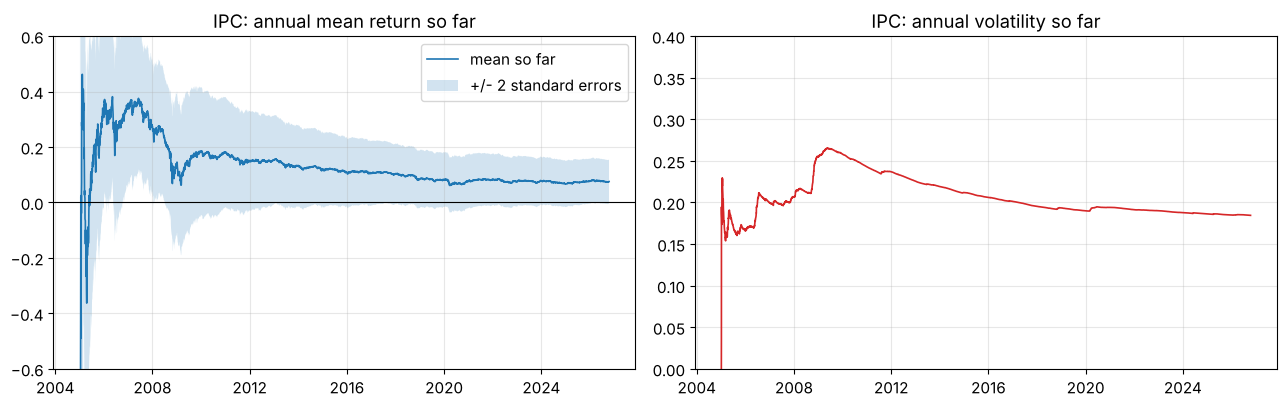

after  1 years: mean +30.63% +/- 33.24%   volatility 16.62%
after  5 years: mean +18.64% +/- 23.05%   volatility 25.77%
after 10 years: mean +11.86% +/- 13.38%   volatility 21.16%
after 20 years: mean +6.91% +/- 8.32%   volatility 18.60%


In [5]:
n = np.arange(1, len(r) + 1)

# running annual mean and volatility, using only the days up to each point
run_mean = r.cumsum() / n * 252
run_vol = np.sqrt((r**2).cumsum() / n - (r.cumsum() / n)**2) * sqrt(252)
band = 2 * run_vol / np.sqrt(n / 252)     # two standard errors of the annual mean

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(r.index, run_mean, lw=1.2, label="mean so far")
ax[0].fill_between(r.index, run_mean - band, run_mean + band, alpha=0.2, label="+/- 2 standard errors")
ax[0].axhline(0, color="black", lw=0.8)
ax[0].set_ylim(-0.6, 0.6); ax[0].set_title("IPC: annual mean return so far"); ax[0].legend()
ax[1].plot(r.index, run_vol, lw=1.2, color="tab:red")
ax[1].set_ylim(0, 0.4); ax[1].set_title("IPC: annual volatility so far")
plt.tight_layout(); plt.show()

for y in [1, 5, 10, 20]:
    i = int(y * 252) - 1
    print(f"after {y:>2} years: mean {run_mean.iloc[i]:+6.2%} +/- {band.iloc[i]:5.2%}   volatility {run_vol.iloc[i]:6.2%}")

The IPC gave around 7.5% per year with a volatility of 18.5%. The interesting part is the plot on the
left. After one year of data the mean was $+30.6\%$, after five years $+18.6\%$, and after twenty years
$+6.9\%$ with a band of $\pm 8.3\%$, which still includes zero. In other words, with twenty years of
history I cannot even say with confidence that the expected return of the Mexican market is positive.
The volatility behaves very differently, since it moves with the crises of 2008 and 2020 but it stays
between 16% and 26% and it is clearly far from zero after a few months. This is why the mean is the
number I should trust the least, even though it is the number most people want to predict.

## 2. The Uniform distribution

The standard uniform $X \sim U(0,1)$ is the simplest continuous distribution: every value between 0
and 1 has the same chance, so its density is flat, $p(x)=1$. Its moments are:

$$\mathbb{E}[X]=\tfrac12, \qquad \sigma^2=\tfrac{1}{12}.$$

A useful fact is that if I put any variable into its own CDF, the result is $U(0,1)$. This gives me a
simple test for a model, because if the model's CDF is correct, the percentiles it gives should be
flat.

**Exercise 2. Are the percentiles flat?** I compute the percentile of each IPC return in two ways:
inside its own history (its rank), and with a normal model that has the same mean and standard
deviation. If the normal model is right, both histograms should be flat.

own history   mean 0.5000 (target 0.5000)   variance 0.0833 (target 0.0833)
normal model  mean 0.5028 (target 0.5000)   variance 0.0674 (target 0.0833)


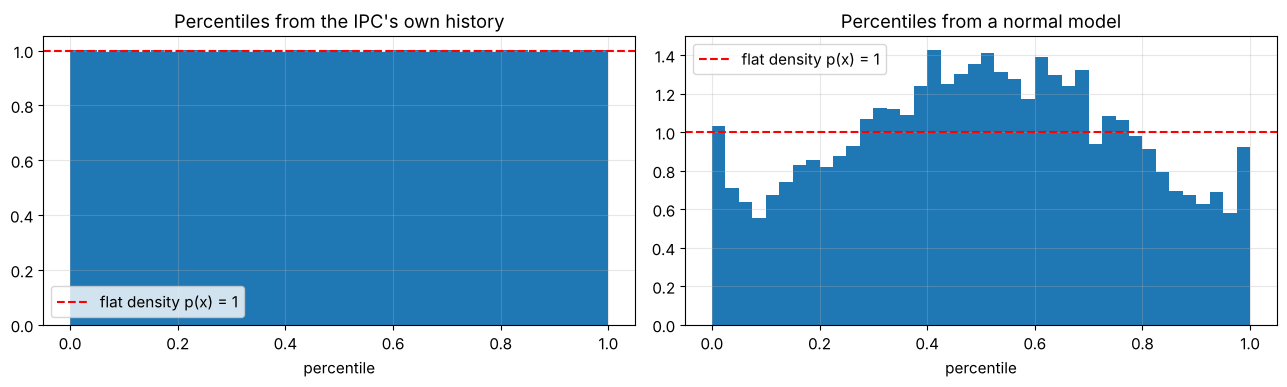

In [6]:
z = ((r - r.mean()) / r.std()).values

# percentile of each day inside its own history: rank / n
u_hist = (np.argsort(np.argsort(z)) + 0.5) / len(z)
# percentile of each day if the returns were normal
u_norm = np.array([normal_cdf(x) for x in z])

for name, u in [("own history", u_hist), ("normal model", u_norm)]:
    print(f"{name:<13} mean {u.mean():.4f} (target 0.5000)   variance {u.var():.4f} (target {1/12:.4f})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, u, title in [(ax[0], u_hist, "Percentiles from the IPC's own history"),
                    (ax[1], u_norm, "Percentiles from a normal model")]:
    a.hist(u, bins=40, density=True)
    a.axhline(1, color="red", ls="--", label="flat density p(x) = 1")
    a.set_title(title); a.set_xlabel("percentile"); a.legend()
plt.tight_layout(); plt.show()

The percentiles from the IPC's own history are flat, with mean 0.5000 and variance 0.0833, which is
exactly $1/12$. The normal model fails the test, since its variance is 0.0674 and its histogram is not
flat at all. It is too high in the middle, because real returns have more quiet days than a normal
predicts, and it goes up again at both edges, because real returns also have more extreme days. So the
uniform is a practical tool: if the percentiles of a risk model are not flat, the model is
wrong, and the shape of the histogram shows where it is wrong.

## 3. Turning uniforms into other distributions (inverse transform)

If I have a target distribution with CDF $F$, and I put a uniform number $u$ into the *inverse* CDF
$F^{-1}$, the result follows that target distribution. The idea is simple: $u$ chooses a percentile,
and $F^{-1}(u)$ gives the value at that percentile.

With real data I do not have a formula for $F$, but I have the sorted returns, and that is enough. The
inverse CDF of the history is just "sort the returns and pick the one at percentile $u$". This is the
idea behind **historical simulation**, one of the most common ways banks compute risk.

**Exercise 3. Historical simulation and Value at Risk.** First I create 100,000 days using only
uniform numbers and the sorted IPC returns, and I check that they look like the history. Then I use
the same idea to compute the one-day **Value at Risk (VaR)**, the loss that is not exceeded on 95% or
99% of the days, and I compare it with the VaR of a normal model.

In [7]:
s = np.sort(r.values)

def empirical_quantile(u):
    # inverse of the empirical CDF: u picks a percentile, the sorted returns give the value
    return s[np.minimum((u * len(s)).astype(int), len(s) - 1)]

# 100,000 days simulated from history using only uniform numbers
sim = empirical_quantile(np.random.rand(100_000))
print(f"simulated: mean {sim.mean():+.5f}  std {sim.std():.5f}")
print(f"history  : mean {r.mean():+.5f}  std {r.std():.5f}\n")

# Value at Risk: the daily loss that is not exceeded on 95% or 99% of the days
z_table = {0.95: 1.6449, 0.99: 2.3263}      # normal quantiles, from the normal table
print(f"{'series':<9}{'level':>7}{'history':>10}{'normal':>9}")
for c in ["IPC", "SPY", "USDMXN"]:
    x = np.log(prices[c].dropna()).diff().dropna()
    xs = np.sort(x.values)
    for level in [0.95, 0.99]:
        hist = -xs[int((1 - level) * len(xs))]
        norm = -(x.mean() - z_table[level] * x.std())
        print(f"{c:<9}{level:>7.0%}{hist:>10.2%}{norm:>9.2%}")

simulated: mean +0.00025  std 0.01159
history  : mean +0.00030  std 0.01162

series     level   history   normal
IPC          95%     1.77%    1.88%
IPC          99%     3.39%    2.67%
SPY          95%     1.76%    1.92%
SPY          99%     3.52%    2.73%
USDMXN       95%     1.03%    1.21%
USDMXN       99%     1.82%    1.71%


The simulated days have almost the same mean and standard deviation as the history, so the method
works, and only uniform numbers went in. For the VaR I use the SPY in dollars and not in pesos, because
the VaR depends on the worst days, and Section 12 shows that on extreme days the SPY in pesos is not
reliable. The VaR table is more interesting. At 95% the normal model
gives a bigger loss than the history for the three series, for example 1.88% against 1.77% for the
IPC. At 99% it is the opposite, and for the IPC the normal model gives 2.67% when the history says
3.39%. This means that a normal model looks conservative on ordinary days and is too optimistic on bad
days, which are exactly the days that a risk number is supposed to cover.

## 4. The Binomial distribution

The binomial counts how many successes happen in $n$ independent yes/no trials, each one with
probability $p$ (and $q=1-p$):

$$P(X=k)=\binom{n}{k}p^k q^{\,n-k}, \qquad \mu = np, \qquad \sigma^2 = npq.$$

In risk management the binomial appears every day. For example, when a bank computes a 99% VaR and
the model is right, each day has a 1% chance of a loss bigger than the VaR, independent of the other
days, so the number of breaches in a year of 250 days follows a $\text{Binomial}(250, 0.01)$.
Regulators use this exact idea: the Basel "traffic light" puts a model in green with 0 to 4 breaches,
yellow with 5 to 9, and red with 10 or more.

**Exercise 4. Testing a normal VaR.** Each day I compute a 99% VaR for the IPC with a normal model and
the volatility of the previous year, and I count the breaches per year. Then I compare the counts with
the binomial formula.

 year  breaches  P(this many or more)   zone
 2006       8            0.0040         yellow
 2007       7            0.0137         yellow
 2008      16            0.0000         red
 2009       1            0.9189         green
 2010       2            0.7142         green
 2011       7            0.0137         yellow
 2012       0            1.0000         green
 2013       7            0.0137         yellow
 2014       3            0.4568         green
 2015       6            0.0412         yellow
 2016       6            0.0412         yellow
 2017       1            0.9189         green
 2018      10            0.0003         red
 2019       0            1.0000         green
 2020      13            0.0000         red
 2021       1            0.9189         green
 2022       2            0.7142         green
 2023       2            0.7142         green
 2024       3            0.4568         green
 2025       2            0.7142         green

mean breaches per year: 4.85   (bi

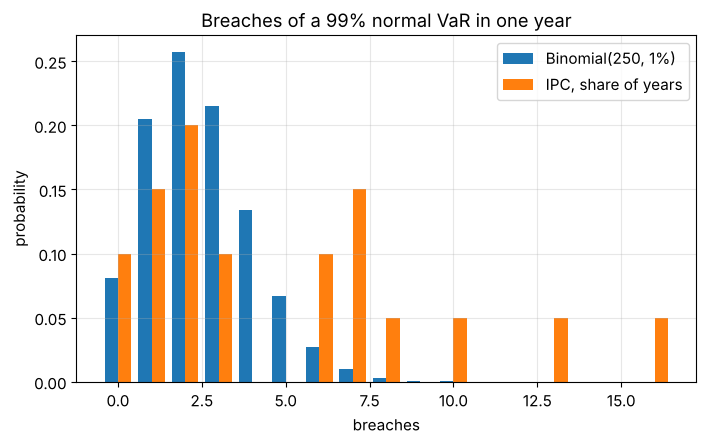

In [8]:
def binom_pmf(k, n, p):
    # exact binomial probability, straight from the definition
    return comb(n, k) * p**k * (1 - p)**(n - k)

# 99% VaR with a normal model and the volatility of the last year (known the day before)
sigma = r.rolling(252).std().shift(1)
breach = (r < -2.3263 * sigma) & sigma.notna()

days = sigma.notna().groupby(sigma.index.year).sum()
per_year = breach.groupby(breach.index.year).sum()[days > 240]   # full years only

# Basel traffic light for 250 days at 99%: green 0-4, yellow 5-9, red 10 or more
zone = lambda k: "green" if k <= 4 else ("yellow" if k <= 9 else "red")
print(" year  breaches  P(this many or more)   zone")
for y, k in per_year.items():
    tail = 1 - sum(binom_pmf(i, 250, 0.01) for i in range(int(k)))
    print(f" {y}     {k:>3}          {tail:8.4f}         {zone(k)}")
print(f"\nmean breaches per year: {per_year.mean():.2f}   (binomial says np = 2.50)")
print(f"variance per year     : {per_year.var():.2f}   (binomial says npq = {250*0.01*0.99:.2f})")

k = np.arange(0, 17)
plt.bar(k - 0.2, [binom_pmf(i, 250, 0.01) for i in k], width=0.4, label="Binomial(250, 1%)")
plt.bar(k + 0.2, np.bincount(per_year.astype(int), minlength=17)[:17] / len(per_year),
        width=0.4, label="IPC, share of years")
plt.title("Breaches of a 99% normal VaR in one year")
plt.xlabel("breaches"); plt.ylabel("probability"); plt.legend(); plt.show()

The model fails the test. A $\text{Binomial}(250, 0.01)$ has a mean of 2.5 breaches per year and a
variance of 2.48, and the IPC had a mean of 4.85 and a variance of 19.71. The model is green in 11 of
the 20 years, yellow in 6 and red in 3: 2008, 2018 and 2020, with 16, 10 and 13 breaches, numbers that
the binomial gives with a probability below 0.1%. The problem is not only that there are too many
breaches, it is that they come together. The binomial assumes that each day is independent, and real
breaches arrive in groups during crises, which is why the variance is so much bigger than the mean. I
will find this same problem again in Sections 6 and 11.

## 5. Watching the Binomial become a bell curve

A binomial is a sum of $n$ independent 0/1 trials, so when $n$ grows it should look more and more
normal. To compare binomials of different sizes on the same axes, I standardize:

$$z = \frac{k - np}{\sqrt{npq}}.$$

A real example of a binomial is the number of days the market goes up. If each day goes up with
probability $p$ and the days are independent, the number of up days in a window of $n$ days is
$\text{Binomial}(n, p)$.

**Exercise 5. Up days in a window.** I count the up days of the SPY in every window of 5, 21 and 63
trading days (a week, a month and a quarter), I standardize the counts and I draw the standard normal
on top.

share of up days for SPY: 0.550



n =  5: mean up days  2.75 (np =  2.75)   std 1.08 (sqrt(npq) = 1.11)
n = 21: mean up days 11.56 (np = 11.55)   std 2.18 (sqrt(npq) = 2.28)


n = 63: mean up days 34.70 (np = 34.64)   std 3.93 (sqrt(npq) = 3.95)


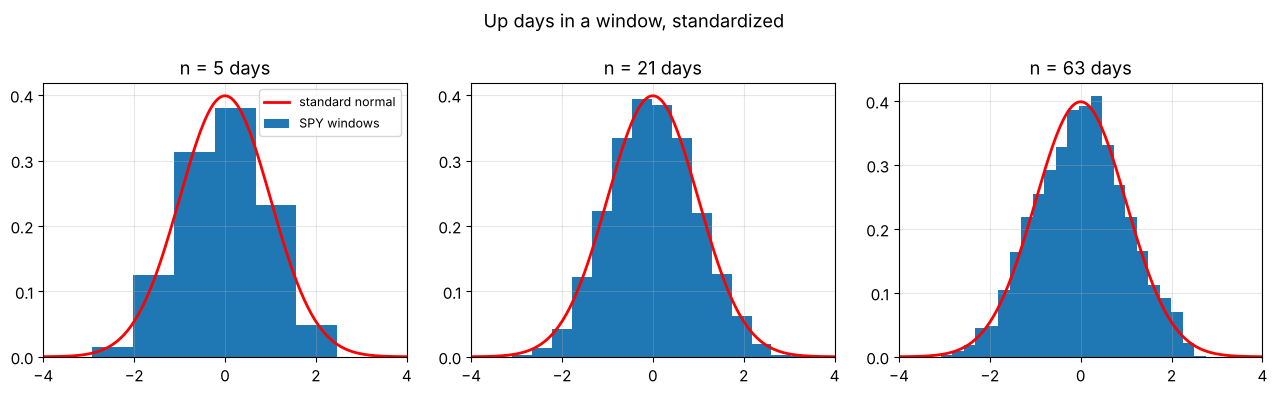

In [9]:
up = (prices["SPY"].dropna().pct_change().dropna() > 0).astype(int).values
p_up = up.mean()
print(f"share of up days for SPY: {p_up:.3f}\n")

z_grid = np.linspace(-4, 4, 200)
std_normal = np.exp(-z_grid**2 / 2) / sqrt(2 * np.pi)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, n in zip(axes, [5, 21, 63]):
    counts = np.convolve(up, np.ones(n), "valid")      # up days in every window of n days
    mu, sd = n * p_up, sqrt(n * p_up * (1 - p_up))
    k = np.arange(0, n + 1)
    share = np.bincount(counts.astype(int), minlength=n + 1) / len(counts)
    ax.bar((k - mu) / sd, share * sd, width=1 / sd, label="SPY windows")
    ax.plot(z_grid, std_normal, color="red", lw=2, label="standard normal")
    ax.set_title(f"n = {n} days"); ax.set_xlim(-4, 4)
    print(f"n = {n:>2}: mean up days {counts.mean():5.2f} (np = {mu:5.2f})   std {counts.std():4.2f} (sqrt(npq) = {sd:4.2f})")
axes[0].legend(fontsize=9)
plt.suptitle("Up days in a window, standardized"); plt.tight_layout(); plt.show()

The SPY went up on 55% of the days, and the counts follow the binomial formula well: in a month the
mean is 11.56 up days against $np = 11.55$, and the standard deviation is 2.18 against 2.28, a bit
smaller. At 5 days the bars are still separated, and at 63 days they are already very close to the red
curve. This was a surprise for me, because Section 4 showed that the days are not independent, and
still the binomial works here. The difference is that the direction of the market, up or down, has
almost no memory, while the size of the moves has a lot of memory, and that is the topic of Section 11.
The windows overlap, so neighboring counts share days, but this does not change the mean, it only
makes the histogram smoother.

## 6. The Poisson distribution: rare events and jumps

If we take the binomial to the limit of many trials with a very small probability, and we keep the
average $\lambda = np$ fixed, we get the **Poisson** distribution:

$$P(X=k)=\frac{\lambda^k e^{-\lambda}}{k!}, \qquad \mu = \lambda, \qquad \sigma^2 = \lambda.$$

The important property is that its mean and its variance are equal. In finance the Poisson is used to
count rare arrivals, like defaults or sudden jumps, and for a Mexican the most important jumps are the
ones of the peso.

**Exercise 6. Extreme days of the peso.** For each year I count the days when USD/MXN moved more than
3 standard deviations. If extreme days arrive like a Poisson process, the mean and the variance of the
yearly counts should be equal.

extreme peso days per year: mean 3.67   variance 33.43   (Poisson says they are equal)
if the returns were normal: 0.68 per year

Date
2005     0
2006     0
2007     0
2008    21
2009     6
2010     2
2011     7
2012     0
2013     1
2014     0
2015     1
2016     8
2017     2
2018     2
2019     2
2020    18
2021     0
2022     1
2023     0
2024     3
2025     3


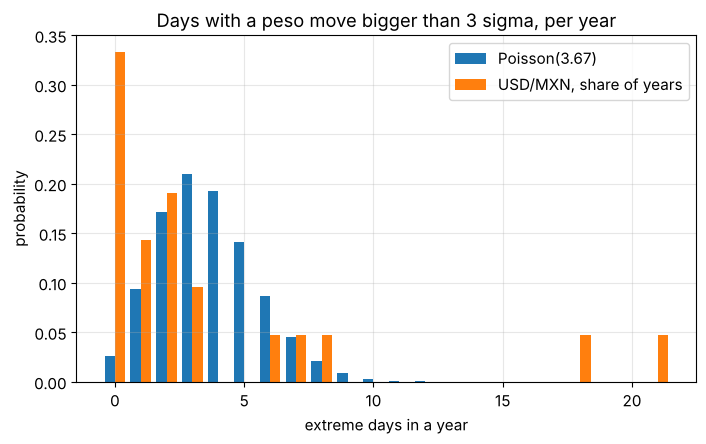

In [10]:
fx = np.log(prices["USDMXN"].dropna()).diff().dropna()
zfx = (fx - fx.mean()) / fx.std()

counts = (zfx.abs() > 3).groupby(zfx.index.year).sum()
counts = counts[counts.index < 2026]      # full years only
lam = counts.mean()

print(f"extreme peso days per year: mean {lam:.2f}   variance {counts.var():.2f}   (Poisson says they are equal)")
print(f"if the returns were normal: {252 * 2 * normal_tail(3):.2f} per year\n")
print(counts.to_string())

def poisson_pmf(k, lam):
    return lam**k * exp(-lam) / np.prod(np.arange(1, k + 1))

k = np.arange(0, counts.max() + 1)
plt.bar(k - 0.2, [poisson_pmf(i, lam) for i in k], width=0.4, label=f"Poisson({lam:.2f})")
plt.bar(k + 0.2, np.bincount(counts, minlength=len(k)) / len(counts), width=0.4, label="USD/MXN, share of years")
plt.title("Days with a peso move bigger than 3 sigma, per year")
plt.xlabel("extreme days in a year"); plt.ylabel("probability"); plt.legend(); plt.show()

On average the peso had 3.67 extreme days per year, more than five times the 0.68 that a normal
distribution predicts. But the main result is that the variance is 33.43, nine times the mean. Most
years have between 0 and 3 extreme days, and then 2008 has 21, 2016 has 8 and 2020 has 18. So the
Poisson is a bad model for the peso, not because of the average, but because extreme days come in
clusters, and one crisis brings many of them together. For a person who saves in pesos this is
important, because the risk of the peso does not arrive spread over time, it arrives all at once.

## 7. The Gaussian and standardization

The normal distribution is the base of the course. Its density,

$$p(x)=\frac{1}{\sqrt{2\pi\sigma^2}}\,e^{-\frac{(x-\mu)^2}{2\sigma^2}},$$

depends on only two numbers, $\mu$ and $\sigma$. Any normal can be moved and rescaled into the
**standard** normal with the Z-score $z=\frac{x-\mu}{\sigma}$, and then the 68–95–99.7 rule says how
many values fall inside one, two and three standard deviations.

**Exercise 7. The rule on real returns.** I standardize the daily returns of five series and I measure
how many fall inside one, two and three standard deviations, and how many are beyond four. A normal
says that in 22 years only about 0.35 days should be beyond four.

In [11]:
print(f"{'series':<9}{'1 sigma':>9}{'2 sigma':>9}{'3 sigma':>9}{'> 4 sigma':>11}{'normal says':>13}")
print(f"{'normal':<9}" + "".join(f"{normal_cdf(s) - normal_cdf(-s):>9.2%}" for s in (1, 2, 3)))
for c in ["IPC", "SPY", "USDMXN", "TLT", "GLD"]:
    x = np.log(prices[c].dropna()).diff().dropna()
    zc = (x - x.mean()) / x.std()            # Z-score: subtract the mean, divide by the std
    inside = "".join(f"{np.mean(zc.abs() < s):>9.2%}" for s in (1, 2, 3))
    print(f"{c:<9}{inside}{int((zc.abs() > 4).sum()):>11d}{len(zc) * 2 * normal_tail(4):>13.2f}")

series     1 sigma  2 sigma  3 sigma  > 4 sigma  normal says
normal      68.27%   95.45%   99.73%
IPC         77.61%   95.39%   98.46%         37         0.35
SPY         80.84%   95.25%   98.38%         40         0.35
USDMXN      78.06%   95.31%   98.59%         36         0.35
TLT         73.77%   95.31%   99.07%         16         0.35
GLD         76.91%   94.80%   98.63%         22         0.35


The middle of the rule works, with around 95% of the days inside two sigma for every series. The rest
does not. Inside one sigma there are between 74% and 81% of the days instead of 68%, so real returns
have more quiet days than a normal, and beyond four sigma there are between 16 and 40 days where a
normal expects less than one. This is the usual shape of financial returns: a high center, thin
shoulders and fat tails. The standard deviation alone hides it, because inside two sigma the two
effects compensate each other. TLT (long US bonds) is the closest to normal and the SPY is the
farthest.

## 8. The Central Limit Theorem, in general

The CLT says that if I add many independent variables with the same distribution, the sum gets close
to a normal distribution, whatever the shape of each part. If each part has mean $\mu$ and variance
$\sigma^2$, the sum of $n$ parts has mean $n\mu$ and variance $n\sigma^2$.

In finance the natural sum is time: a monthly log return is the sum of about 21 daily log returns. If
the CLT works, monthly and quarterly returns should look more normal than daily ones.

**Exercise 8. Adding up days.** I add daily log returns into weekly, monthly and quarterly returns
without overlap, and I compute the skewness and the excess kurtosis at each horizon. Both should get
close to 0.

series    days   obs    skew  ex. kurt
IPC          1  5466   -0.04      5.99
IPC          5  1093   -0.25      6.05
IPC         21   260   -0.24      2.45
IPC         63    86   -0.01      0.14

SPY          1  5479   -0.30     14.77
SPY          5  1095   -0.95     10.60
SPY         21   260   -0.87      4.01
SPY         63    86   -0.84      0.57

USDMXN       1  5455    0.74      9.37
USDMXN       5  1091    0.88      4.74
USDMXN      21   259    1.19      5.89
USDMXN      63    86    1.58      4.79



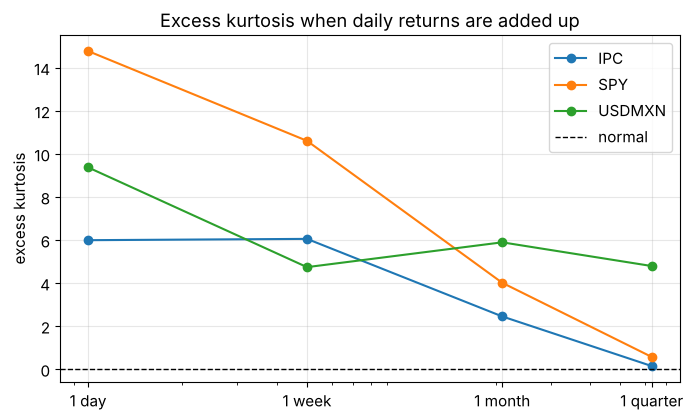

In [12]:
def skew_kurt(x):
    c = x - x.mean()
    return np.mean(c**3) / x.std()**3, np.mean(c**4) / x.std()**4 - 3

horizons = [1, 5, 21, 63]
print(f"{'series':<8}{'days':>6}{'obs':>6}{'skew':>8}{'ex. kurt':>10}")
for c in ["IPC", "SPY", "USDMXN"]:
    x = np.log(prices[c].dropna()).diff().dropna().values
    ks = []
    for h in horizons:
        m = len(x) // h
        sums = x[:m * h].reshape(m, h).sum(axis=1)      # returns over h days, no overlap
        sk, ku = skew_kurt(sums)
        ks.append(ku)
        print(f"{c:<8}{h:>6}{m:>6}{sk:>8.2f}{ku:>10.2f}")
    plt.plot(horizons, ks, "o-", label=c)
    print()
plt.axhline(0, color="black", ls="--", lw=1, label="normal")
plt.xscale("log"); plt.xticks(horizons, ["1 day", "1 week", "1 month", "1 quarter"])
plt.title("Excess kurtosis when daily returns are added up"); plt.ylabel("excess kurtosis")
plt.legend(); plt.show()

For the IPC and the SPY the CLT works: the excess kurtosis falls from 6.0 and 14.8 at one day to 0.14
and 0.57 at one quarter. It takes much longer than with independent variables, and the SPY keeps a
negative skew of $-0.84$ even at one quarter, which means its big moves are more often down. The peso
does not follow the rule. Its kurtosis goes from 9.4 to 4.8 and stays high, and its skewness grows
from 0.74 to 1.58, so the quarterly returns of the dollar in pesos are even more asymmetric than the
daily ones. The reason is that the peso does not lose value in many small steps, it loses it in a few
weeks of crisis, and adding days together does not remove that. With only 86 quarters these numbers
are noisy, so I trust the direction more than the exact values.

## 9. From normal returns to lognormal prices

Prices cannot be negative, so the usual model assumes that the **log return** is normal. If
$r \sim N(\mu, \sigma^2)$, then the price multiplier $Y=e^{r}$ is **lognormal**, always positive, and

$$\mathbb{E}[Y] = e^{\,\mu + \sigma^2/2}.$$

The extra $\sigma^2/2$ also appears over long horizons: the average of the returns is bigger than the
rate at which the money really grows, and the difference is close to $\sigma^2/2$.

**Exercise 9. The $\sigma^2/2$ term in real data.** First I check $\mathbb{E}[e^r] = e^{\mu+\sigma^2/2}$
with the IPC's daily returns. Then I compare, for five series, the yearly average of the simple
returns with the CAGR, the rate at which the money actually grew.

In [13]:
Y = np.exp(r)                                  # daily price multiplier e^r
print(f"IPC daily multiplier: empirical E[Y] {Y.mean():.6f}   e^(mu + sigma^2/2) {exp(r.mean() + r.var() / 2):.6f}   e^mu {exp(r.mean()):.6f}")
print(f"smallest multiplier: {Y.min():.4f} (always > 0)\n")

# the same sigma^2/2 over years: average of simple returns vs what the money did (CAGR)
print(f"{'series':<9}{'average':>9}{'CAGR':>8}{'gap':>7}{'sigma^2/2':>11}")
for c in ["IPC", "SPY", "SPY_MXN", "EEM", "GLD"]:
    px = prices[c].dropna()
    R = px.pct_change().dropna()
    years = len(R) / 252
    avg = R.mean() * 252
    cagr = (px.iloc[-1] / px.iloc[0])**(1 / years) - 1
    print(f"{c:<9}{avg:>9.2%}{cagr:>8.2%}{avg - cagr:>7.2%}{R.var() * 252 / 2:>11.2%}")

IPC daily multiplier: empirical E[Y] 1.000367   e^(mu + sigma^2/2) 1.000367   e^mu 1.000299
smallest multiplier: 0.9299 (always > 0)

series     average    CAGR    gap  sigma^2/2
IPC          9.24%   7.83%  1.41%      1.70%
SPY         12.14%  10.91%  1.23%      1.78%
SPY_MXN     14.51%  13.67%  0.84%      1.70%
EEM         10.66%   7.10%  3.56%      3.81%
GLD         11.65%  10.49%  1.16%      1.67%


With daily data the formula works to six decimals (1.000367 against 1.000367), while $e^{\mu}$ alone
gives 1.000299, and the smallest multiplier is 0.93, so the price never goes below zero. The second
table shows why this matters. The average return of the IPC is 9.24% per year, but the money actually
grew at 7.83% per year, and the gap of 1.41% is close to $\sigma^2/2 = 1.70\%$. For emerging markets
(EEM) the gap is 3.56%, because their volatility is higher. So an average return is not what an
investor earned, and the difference grows with the volatility. Note that the IPC series
is a price index without dividends, so both of its numbers are lower than what an investor in the
index really received.

## 10. Chaining returns into a price path

A price after many days is built from a **sum of log returns**:

$$S_T = S_0\,\exp\!\Big(\sum_{t=1}^{T} r_t\Big).$$

For a Mexican this sum has a very useful property. The log return of the SPY in pesos is exactly the
log return of the SPY in dollars plus the log return of the dollar in pesos,

$$r^{\text{SPY, MXN}}_t = r^{\text{SPY, USD}}_t + r^{\text{USD/MXN}}_t,$$

so holding a dollar asset means holding two random variables at the same time, and the variance of a
sum tells me how risky it is: $\sigma^2_{\text{MXN}} = \sigma^2_{\text{SPY}} + \sigma^2_{\text{FX}} +
2\,\text{Cov}(r^{\text{SPY}}, r^{\text{FX}})$.

**Exercise 10. 100 pesos in Mexico and in the US.** I check that the decomposition is exact, I chain
the daily returns into the value of 100 invested in 2005, and I compute the volatility of the SPY in
pesos from its two parts.

largest gap between SPY_MXN and SPY + USDMXN: 2.2e-15



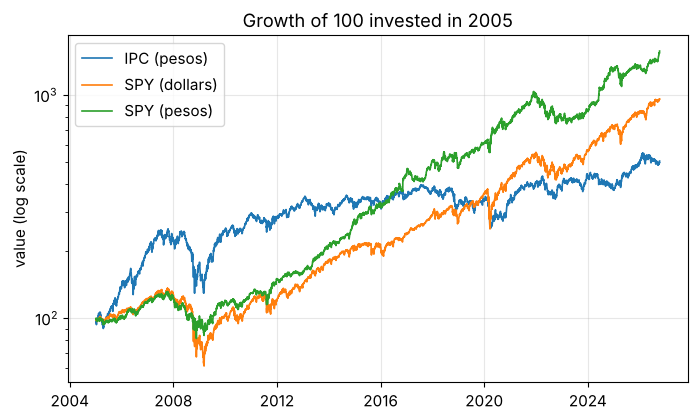

IPC         507.0
SPY         962.0
SPY_MXN    1577.0

volatility SPY in dollars: 19.03%
volatility USD/MXN       : 11.92%
correlation              : -0.36
volatility SPY in pesos  : 18.41%  (formula)  18.41%  (data)


In [14]:
lr = log_returns(["SPY", "USDMXN", "SPY_MXN", "IPC"])

# in log returns, the peso view is an exact sum: SPY in dollars + the dollar in pesos
print(f"largest gap between SPY_MXN and SPY + USDMXN: {(lr['SPY_MXN'] - lr['SPY'] - lr['USDMXN']).abs().max():.1e}\n")

# a price path is the running sum of log returns, then an exponential
growth = 100 * np.exp(lr[["IPC", "SPY", "SPY_MXN"]].cumsum())
for c, label in [("IPC", "IPC (pesos)"), ("SPY", "SPY (dollars)"), ("SPY_MXN", "SPY (pesos)")]:
    plt.plot(growth.index, growth[c], lw=1.2, label=label)
plt.yscale("log"); plt.title("Growth of 100 invested in " + str(lr.index[0].year))
plt.ylabel("value (log scale)"); plt.legend(); plt.show()
print(growth.iloc[-1].round(0).to_string())

# variance of a sum: var(SPY) + var(FX) + 2 cov
v_spy, v_fx = lr["SPY"].var() * 252, lr["USDMXN"].var() * 252
cov = lr["SPY"].cov(lr["USDMXN"]) * 252
print(f"\nvolatility SPY in dollars: {sqrt(v_spy):.2%}")
print(f"volatility USD/MXN       : {sqrt(v_fx):.2%}")
print(f"correlation              : {lr['SPY'].corr(lr['USDMXN']):+.2f}")
print(f"volatility SPY in pesos  : {sqrt(v_spy + v_fx + 2 * cov):.2%}  (formula)  {lr['SPY_MXN'].std() * sqrt(252):.2%}  (data)")

The decomposition is exact up to rounding ($10^{-15}$). Since 2005, 100 pesos in the IPC became 507,
100 dollars in the SPY became 962 dollars, and 100 pesos in the SPY became 1,577 pesos, because the
peso also went from around 11.2 to around 18.4 per dollar. The number I did not expect is the
volatility. The SPY in dollars has 19.0%, the dollar in pesos adds a second source of risk of 11.9%,
and still the SPY in pesos has a lower volatility, 18.4%. This happens because the correlation between
the two is $-0.36$: when the US market falls the peso usually gets weaker, and the gain on the dollar
covers part of the loss. This is why, for a Mexican, owning the SPY is less risky than it looks from
the US.

Section 0 showed that the FRED rate is measured at noon, a few hours before the SPY closes. To be sure
that this result is not a timing effect, I repeat the comparison with weekly and monthly prices, where
a difference of a few hours no longer matters.

In [15]:
# the same check with weekly and monthly prices, where a few hours of difference no longer matter
x = prices[["SPY", "USDMXN", "SPY_MXN"]].dropna()
print(f"{'frequency':<10}{'SPY in dollars':>16}{'SPY in pesos':>14}{'corr SPY-FX':>13}")
for name, rule, k in [("daily", None, 252), ("weekly", "W-FRI", 52), ("monthly", "ME", 12)]:
    p = x if rule is None else x.resample(rule).last()
    lr = np.log(p).diff().dropna()
    print(f"{name:<10}{lr['SPY'].std() * sqrt(k):>16.2%}{lr['SPY_MXN'].std() * sqrt(k):>14.2%}{lr['SPY'].corr(lr['USDMXN']):>+13.2f}")

frequency   SPY in dollars  SPY in pesos  corr SPY-FX
daily               18.91%        18.41%        -0.35
weekly              17.60%        14.92%        -0.55
monthly             14.87%        12.69%        -0.56


The result holds and it gets stronger. With monthly data the SPY has a volatility of 14.9% in dollars
and 12.7% in pesos, and the correlation with the peso goes from $-0.35$ with daily data to $-0.56$. So the noon timing
makes the daily effect look smaller, it does not create it.

## 11. Correlation is not dependence

Covariance and correlation only measure *linear* co-movement:

$$\rho_{XY} = \frac{\mathrm{Cov}(X,Y)}{\sigma_X \sigma_Y} \in [-1, 1].$$

People often read a correlation of zero as "not related", but that is a mistake, because two variables
can be strongly connected and still have zero correlation. Real returns give a clear example of this.

**Exercise 11. Returns and their size.** For the SPY I compute the autocorrelation of the daily
returns and of their absolute values, for lags of 1 to 20 days. Values inside $\pm 2/\sqrt{T}$ are
noise.

lag  1: returns -0.101   size of returns +0.318
lag 20: returns +0.024   size of returns +0.228
noise band: +/- 0.027


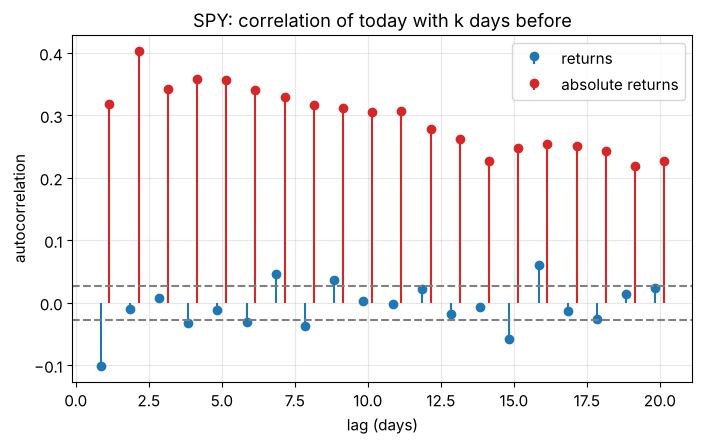

In [16]:
def acf(x, k):
    x = x - x.mean()
    return np.sum(x[k:] * x[:len(x) - k]) / np.sum(x * x)

x = np.log(prices["SPY"].dropna()).diff().dropna().values
lags = np.arange(1, 21)
ac_r = [acf(x, k) for k in lags]
ac_abs = [acf(np.abs(x), k) for k in lags]
band = 2 / sqrt(len(x))

print(f"lag  1: returns {ac_r[0]:+.3f}   size of returns {ac_abs[0]:+.3f}")
print(f"lag 20: returns {ac_r[19]:+.3f}   size of returns {ac_abs[19]:+.3f}")
print(f"noise band: +/- {band:.3f}")

plt.stem(lags - 0.15, ac_r, linefmt="C0-", markerfmt="C0o", basefmt=" ", label="returns")
plt.stem(lags + 0.15, ac_abs, linefmt="C3-", markerfmt="C3o", basefmt=" ", label="absolute returns")
plt.axhline(band, color="gray", ls="--"); plt.axhline(-band, color="gray", ls="--")
plt.title("SPY: correlation of today with k days before")
plt.xlabel("lag (days)"); plt.ylabel("autocorrelation"); plt.legend(); plt.show()

The returns themselves have almost no memory. Lag 1 is $-0.10$, which is outside the band but small,
and after that the blue bars stay close to zero. The absolute returns are different, since lag 1 is
$+0.32$ and lag 20 is still $+0.23$, far outside the band. This means that a big move today, up or
down, makes a big move tomorrow more likely, but it says almost nothing about the direction. This is
the same thing I found with the VaR breaches and the extreme peso days: the days are close to
uncorrelated, but they are not independent, and a model that only looks at correlation misses it.

## 12. Fat tails

The tails of a Gaussian fall like $e^{-x^2}$, so extreme values are almost impossible. Real returns
have **fat tails** that fall much more slowly. The course shows this with the Cauchy distribution, and
here I use the biggest days of real series instead.

**Exercise 12. The biggest days.** For the IPC, the SPY and the peso, I list the five biggest
moves in standard deviations, and how often a normal distribution would produce each one. Then I
compare the running volatility of the peso with a normal sample that has the same volatility.

IPC: five biggest moves


   2008-10-13  +10.44%   +9.0 sigma   a normal says once every 2e+16 years
   2008-10-28   +9.81%   +8.4 sigma   a normal says once every 2e+14 years
   2008-10-22   -7.27%   -6.3 sigma   a normal says once every 2e+07 years
   2008-11-24   +6.77%   +5.8 sigma   a normal says once every 1e+06 years
   2020-03-09   -6.64%   -5.7 sigma   a normal says once every 8e+05 years

SPY: five biggest moves
   2008-10-13  +13.56%  +11.4 sigma   a normal says once every 1e+27 years
   2020-03-16  -11.59%   -9.8 sigma   a normal says once every 6e+19 years
   2008-10-28  +11.05%   +9.3 sigma   a normal says once every 4e+17 years
   2008-10-15  -10.36%   -8.7 sigma   a normal says once every 4e+15 years
   2020-03-12  -10.06%   -8.5 sigma   a normal says once every 4e+14 years

USDMXN: five biggest moves
   2008-10-08   +8.11%  +11.0 sigma   a normal says once every 1e+25 years
   2016-11-09   +7.01%   +9.5 sigma   a normal says once every 3e+18 years
   2008-10-09   -5.96%   -8.1 sigma   a normal 

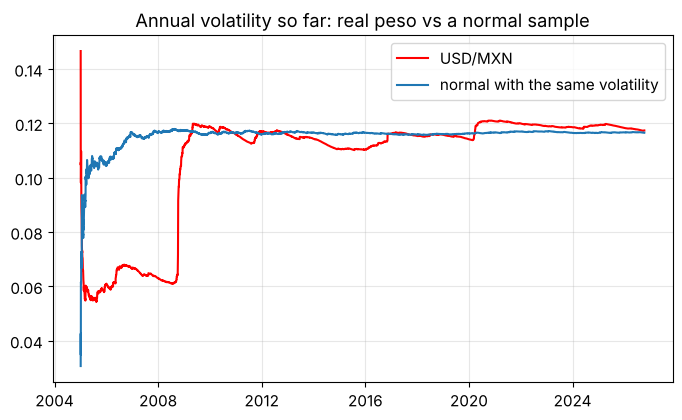

In [17]:
for c in ["IPC", "SPY", "USDMXN"]:
    x = np.log(prices[c].dropna()).diff().dropna()
    zc = (x - x.mean()) / x.std()
    print(f"{c}: five biggest moves")
    for d in zc.abs().sort_values(ascending=False).index[:5]:
        years = 1 / (normal_tail(abs(zc[d])) * 252)     # how often a normal would give this move
        print(f"   {d.date()}  {x[d]:+7.2%}  {zc[d]:+5.1f} sigma   a normal says once every {years:.0e} years")
    print()

# running variance: does it settle like a normal sample would?
x = np.log(prices["USDMXN"].dropna()).diff().dropna()
fake = np.random.normal(x.mean(), x.std(), len(x))
n = np.arange(1, len(x) + 1)
plt.plot(x.index, np.sqrt((x**2).cumsum() / n) * sqrt(252), color="red", label="USD/MXN")
plt.plot(x.index, np.sqrt(np.cumsum(fake**2) / n) * sqrt(252), label="normal with the same volatility")
plt.title("Annual volatility so far: real peso vs a normal sample")
plt.legend(); plt.show()

The biggest day of the IPC, October 13, 2008, was a move of 9 sigma, and a normal says this should
happen once every $10^{16}$ years. The SPY had an 11.4 sigma day on the same date, and the peso had an
11 sigma day in October 2008 and a 9.5 sigma day the day after the US election of November 2016. All of
these days happened in the last 22 years, and most of them in October 2008 and March 2020.

The plot shows the same problem in another way. A normal sample settles in a few months, while the
real peso had a volatility of around 6% before 2008, and one month of crisis doubled it. This means
that the history before a crisis says very little about the size of the next one.

I left the SPY in pesos out of this section on purpose. In a first version it appeared with a
$-13.2\%$ day on October 9, 2008, and I wanted to know if that day was real. The next cell compares the
same two days with the FRED rate, measured at noon, and with the Yahoo rate, which in 2008 was still
recorded at the end of the day (Section 0).

In [18]:
# why the SPY in pesos is left out of the daily tails: the same days with the two exchange rates
x = prices[["SPY", "USDMXN", "USDMXN_YF"]].dropna()
lr = np.log(x).diff().loc["2008-10-08":"2008-10-09"] * 100
tab = pd.DataFrame({
    "USD/MXN, FRED (noon)": lr["USDMXN"],
    "USD/MXN, Yahoo (end of day)": lr["USDMXN_YF"],
    "SPY in pesos with FRED": lr["SPY"] + lr["USDMXN"],
    "SPY in pesos with Yahoo": lr["SPY"] + lr["USDMXN_YF"],
})
tab.loc["both days"] = tab.sum()
tab.index = [i.strftime("%b %d, %Y") if hasattr(i, "strftime") else i for i in tab.index]
print("daily log returns, %")
print(tab.T.round(1).to_string())

daily log returns, %
                             Oct 08, 2008  Oct 09, 2008  both days
USD/MXN, FRED (noon)                  8.1          -6.0        2.2
USD/MXN, Yahoo (end of day)           0.1           9.3        9.3
SPY in pesos with FRED                5.6         -13.2       -7.6
SPY in pesos with Yahoo              -2.5           2.0       -0.4


The two sources tell completely different stories. With FRED, the dollar jumped 8.1% on October 8 and
fell 6.0% on October 9, and the SPY in pesos lost 13.2% on the second day. With Yahoo, the big move of
the dollar came one day later, and the SPY in pesos gained 2.0%, a normal day. In those days the peso
moved so much inside each day that measuring it at noon or at the close changes the result completely.
So on extreme days, the daily SPY in pesos built with the noon rate is not reliable, and this is why the
tails and the VaR in this notebook use the SPY in dollars. The results in pesos are kept for Section 10,
where they are also checked with weekly and monthly data.

## 13. Diversification

For a portfolio with weights $w_i$, volatilities $\sigma_i$ and correlations $\rho_{ij}$, the variance
is

$$\sigma_p^2 = \sum_i w_i^2 \sigma_i^2 + \sum_{i\neq j} w_i w_j\, \sigma_i \sigma_j\, \rho_{ij}
            \;=\; \mathbf{w}^\top \mathbf{\Sigma}\, \mathbf{w}.$$

The expected return is only the weighted average of the parts, but the risk depends on the
correlations. The clean $\sigma_0/\sqrt{n}$ rule needs correlations of zero, and real correlations are
not zero. For a Mexican they also have to be measured in pesos.

**Exercise 13. A portfolio in pesos.** First I compute the correlations of six assets measured in
pesos: the IPC, the SPY, emerging markets, long US bonds, gold, and the dollar itself. Then I compare
an equal-weight portfolio with the average of the volatilities and with the case of zero correlation.

In [19]:
assets = ["IPC", "SPY_MXN", "EEM_MXN", "TLT_MXN", "GLD_MXN", "USDMXN"]
lr = log_returns(assets)
vols = lr.std() * sqrt(252)
print("correlations, everything measured in pesos:")
print(lr.corr().round(2).to_string())

w = np.full(len(assets), 1 / len(assets))
Sigma = lr.cov().values * 252
print(f"\nequal weights, real correlations: {sqrt(w @ Sigma @ w):.2%}")
print(f"weighted average of volatilities: {w @ vols.values:.2%}")
print(f"if every correlation were zero  : {sqrt(np.sum((w * vols.values)**2)):.2%}")

correlations, everything measured in pesos:
          IPC  SPY_MXN  EEM_MXN  TLT_MXN  GLD_MXN  USDMXN
IPC      1.00     0.42     0.59    -0.38    -0.10   -0.38
SPY_MXN  0.42     1.00     0.76    -0.00     0.14    0.27
EEM_MXN  0.59     0.76     1.00    -0.16     0.14    0.01
TLT_MXN -0.38    -0.00    -0.16     1.00     0.42    0.68
GLD_MXN -0.10     0.14     0.14     0.42     1.00    0.44
USDMXN  -0.38     0.27     0.01     0.68     0.44    1.00



equal weights, real correlations: 11.03%
weighted average of volatilities: 19.07%
if every correlation were zero  : 7.94%


An equal-weight portfolio of the six assets has a volatility of 11.0%, against an average of 19.1% for
the individual assets, so diversification removes around 42% of the risk. It does not reach the 7.9%
of the zero-correlation case, because the correlations are not zero. The matrix also shows something
particular to a Mexican. The long US bonds in pesos (TLT_MXN) have a correlation of 0.68 with the
dollar, so for a Mexican they are mostly a position in the dollar and only partly a position in US
interest rates. The IPC has a correlation of $-0.38$ with the dollar, which is the effect of Section 10
seen from the other side.

To finish, I compare the same two markets, Mexico and the US, measured in pesos and in dollars.

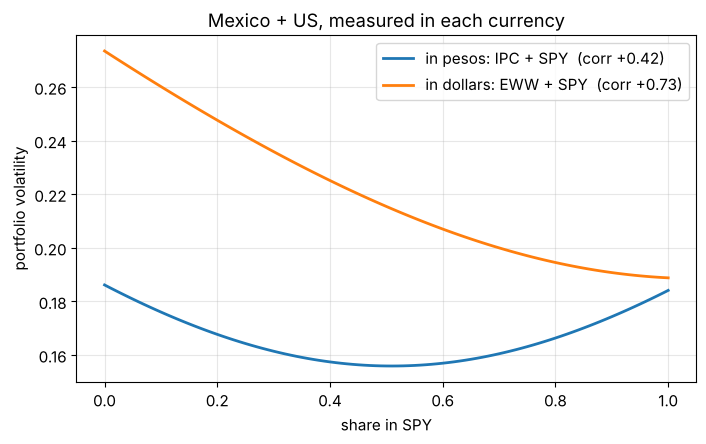

pesos    0% SPY 18.62%   100% SPY 18.41%   lowest 15.59% at 51% SPY
dollars  0% SPY 27.35%   100% SPY 18.88%   lowest 18.88% at 100% SPY


In [20]:
def two_asset(a, b):
    lr = log_returns([a, b])
    S = lr.cov().values * 252
    ws = np.linspace(0, 1, 101)
    return ws, np.array([sqrt(np.array([1 - x, x]) @ S @ np.array([1 - x, x])) for x in ws]), lr[a].corr(lr[b])

ws, v_mx, c_mx = two_asset("IPC", "SPY_MXN")     # a saver in pesos
ws, v_us, c_us = two_asset("EWW", "SPY")         # the same two markets seen from the US, in dollars

plt.plot(ws, v_mx, lw=2, label=f"in pesos: IPC + SPY  (corr {c_mx:+.2f})")
plt.plot(ws, v_us, lw=2, label=f"in dollars: EWW + SPY  (corr {c_us:+.2f})")
plt.title("Mexico + US, measured in each currency")
plt.xlabel("share in SPY"); plt.ylabel("portfolio volatility"); plt.legend(); plt.show()

for name, v in [("pesos", v_mx), ("dollars", v_us)]:
    i = v.argmin()
    print(f"{name:<8} 0% SPY {v[0]:.2%}   100% SPY {v[-1]:.2%}   lowest {v[i]:.2%} at {ws[i]:.0%} SPY")

This is the result I find most useful from the whole module. Take two investors who split their money
between Mexico and the US. The investor in the US measures everything in dollars, and for
him Mexico (EWW) has a volatility of 27.4% and a correlation of 0.73 with the SPY, so the lowest risk
is to hold 100% SPY and Mexico adds nothing. The investor in Mexico measures in pesos, the IPC has a
volatility of 18.6% and a correlation of 0.42 with the SPY, and the lowest risk is around half and
half, with 15.6%, lower than either market alone. The two markets are the same, and the only
difference is the currency in which each person lives. Diversification is not a property of the assets
alone, it also depends on who holds them.

## Wrapping up Module 1

The course built these ideas with simulated numbers, and here I tested each one with real prices. The
results split in two groups. The formulas that describe averages work well: the count of up days, the
variance of a sum and the $\sigma^2/2$ term of the lognormal all matched the history. The formulas
that need independence or thin tails fail, and always in the same way, since VaR breaches, extreme
peso days and big moves arrive in groups, and the biggest days are 9 to 11 sigma events.

The point of view also matters. For a person who saves in pesos, the dollar is a second source of risk
that also protects during crises, and two markets that look redundant from the US diversify well from
Mexico.

Twenty-two years is not a long history for rare events, and some conclusions about the tails depend on
a few crises, but the same pattern appears in every series and in every test. The tools of this module
are correct, and what has to be checked against real data are the assumptions behind them.

The next step is to let these sums develop over time, which is where Module 2 begins.